# Comparing Climate Indicator Engines: icclim vs xclim

**earthkit-climate** wraps two leading scientific climate index calculation engines under a unified Earthkit API:

1. **xclim**: A comprehensive, CF-compliant climate indicator library developed by Ouranos, featuring more than 80 indices and optimized resampling with flox.
2. **icclim**: An ECA&D/C3S-compliant index library developed by CERFACS, focused on the standard 49 ECA&D indices with native 5-day running window percentile bootstrapping.

This guide explores:
- **Fixed-threshold indicators**: Verifying mathematical equivalence between homologous indices (such as `fd` vs `frost_days` and `cdd` vs `maximum_consecutive_dry_days`).
- **Percentile-based indicators & backends**: Using `tx90p` and `tn10p` with `backend="auto"`, `backend="icclim"`, or `backend="xclim"`.
- **Methodological differences**: Comparing precomputed percentile arrays (xclim) against on-the-fly running-window bootstrapping (icclim).
- **Scalability with Dask**: Preserving lazy execution and chunking.
- **Engine Selection Guide**: A quick-reference matrix to help choose the best engine for your workflow.

## 1. Environment Setup and Sample Climate Data

We load the `synthetic-daily-comparison` sample dataset via `earthkit.data.from_source()`. It provides a synthetic 10-year daily meteorological dataset (1990-1999) with realistic seasonal variations for maximum temperature (`tasmax`), minimum temperature (`tasmin`), and daily precipitation (`pr`).

In [1]:
import warnings

import earthkit.data as ekd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xclim
import xclim.core.calendar as xcal

from earthkit.climate import indicators

# Configure xclim to log CF compliance checks instead of emitting console UserWarnings
warnings.filterwarnings("ignore", category=UserWarning, module="xclim.*")
xclim.set_options(cf_compliance="log")

# Load 10 years of synthetic daily meteorological data (1990-1999) via earthkit-data
ds = ekd.from_source("earthkit-climate-sample", "synthetic-daily-comparison").to_xarray()
print(f"Dataset loaded with {len(ds.time)} daily steps from {ds.time.values[0]} to {ds.time.values[-1]}.")
ds

Dataset loaded with 3652 daily steps from 1990-01-01T00:00:00.000000000 to 1999-12-31T00:00:00.000000000.


/home/cuadradot/predictia_projects/git/c3s-indices/earthkit-climate/src/earthkit/climate/_sample_source.py:391: UserWarning: earthkit-climate-sample datasets are made available for demonstration purposes only. Files are not guaranteed to be available long-term and may change over time. Please use official channels to obtain the contained datasets reliably for other purposes.
  warnings.warn(


<xarray.Dataset> Size: 117kB
Dimensions:  (time: 3652)
Coordinates:
  * time     (time) datetime64[ns] 29kB 1990-01-01 1990-01-02 ... 1999-12-31
Data variables:
    tasmax   (time) float64 29kB 8.182 4.193 9.613 10.24 ... 7.3 11.47 7.987
    tasmin   (time) float64 29kB -0.5988 -0.889 -1.08 ... -4.352 -4.209 -3.08
    pr       (time) float64 29kB 1.816 5.065 2.673 0.0 0.0 ... 0.0 0.0 0.0 0.0

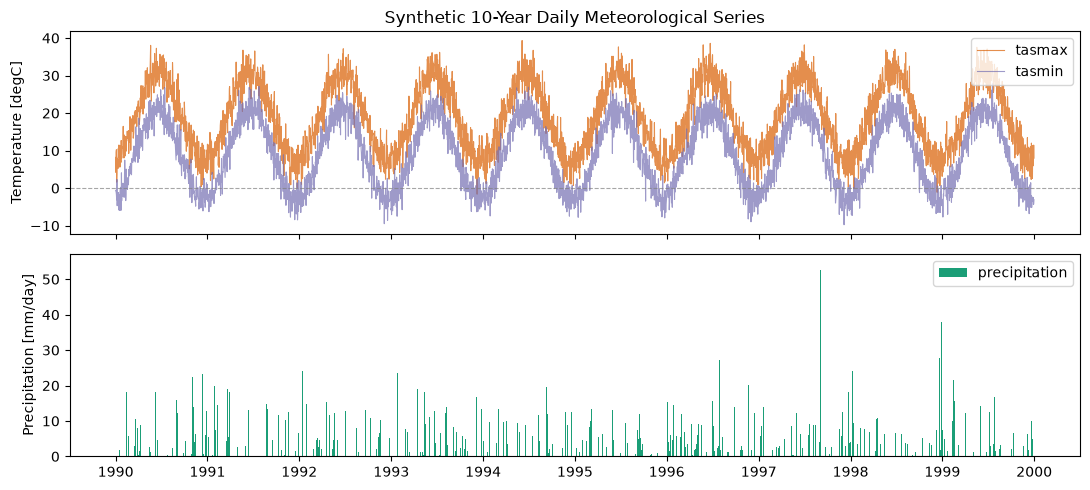

In [2]:
# Quick overview of the sample time series
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)

ax1.plot(ds["time"], ds["tasmax"], label="tasmax", color="#d95f02", alpha=0.7, lw=0.8)
ax1.plot(ds["time"], ds["tasmin"], label="tasmin", color="#7570b3", alpha=0.7, lw=0.8)
ax1.axhline(0, color="gray", ls="--", lw=0.8, alpha=0.7)
ax1.set_ylabel("Temperature [degC]")
ax1.legend(loc="upper right")
ax1.set_title("Synthetic 10-Year Daily Meteorological Series")

ax2.bar(ds["time"], ds["pr"], width=1.0, color="#1b9e77", label="precipitation")
ax2.set_ylabel("Precipitation [mm/day]")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 2. Fixed-Threshold Indicators: Numerical Equivalence and Boundary Nuances

When an indicator relies on daily fixed physical thresholds without multi-day spell tracking across periods (such as frost days with $TN < 0^\circ\text{C}$ or summer days with $TX > 25^\circ\text{C}$), `icclim` and `xclim` produce **100% identical numerical results**.

For multi-day spell indicators like **Consecutive Dry Days (CDD)**, they agree across virtually all years, with subtle differences occurring only when a prolonged dry spell crosses the December 31 / January 1 year boundary:
- **xclim**: Truncates run length calculations at the annual resample boundary.
- **icclim**: Follows ECA&D criteria allowing spell lengths to continue across year boundaries and attributing them according to ECA&D rules.

In [3]:
# 1. Frost Days (TN < 0 degC)
fd_icclim = indicators.fd(ds["tasmin"], freq="YS")
fd_xclim = indicators.frost_days(ds["tasmin"], freq="YS")

# Verify strict numerical equality
np.testing.assert_allclose(fd_icclim.values, fd_xclim.values)
print("Frost days (FD) are 100% identical across all 10 years.")

# 2. Maximum Consecutive Dry Days (RR < 1 mm/day)
cdd_icclim = indicators.cdd(ds["pr"], freq="YS")
cdd_xclim = indicators.maximum_consecutive_dry_days(ds["pr"], freq="YS")

# Display comparative table
df_comp = pd.DataFrame({
    "Year": [t.year for t in pd.to_datetime(fd_icclim.time.values)],
    "icclim FD": fd_icclim.values.astype(int),
    "xclim Frost Days": fd_xclim.values.astype(int),
    "icclim CDD": cdd_icclim.values.astype(int),
    "xclim Max Cons Dry Days": cdd_xclim.values.astype(int),
})

# Highlight boundary year difference
df_comp["CDD Match"] = df_comp["icclim CDD"] == df_comp["xclim Max Cons Dry Days"]
print("Annual Comparison:")
df_comp

Frost days (FD) are 100% identical across all 10 years.
Since icclim 7.4.0, CDD defaults to run_index="last", so a run crossing a period boundary is counted where it ends. Use run_index="first" for the pre-7.4.0 result, or split_runs_at_period_boundary=True to cut the run at each boundary.


Annual Comparison:


,Year,icclim FD,xclim Frost Days,icclim CDD,xclim Max Cons Dry Days,CDD Match
0,1990,82,82,20,20,True
1,1991,85,85,20,20,True
2,1992,90,90,24,24,True
3,1993,79,79,21,21,True
4,1994,83,83,18,18,True
5,1995,83,83,13,13,True
6,1996,69,69,16,16,True
7,1997,73,73,19,19,True
8,1998,83,83,15,15,True
9,1999,73,73,22,22,True


## 3. Percentile-based Indicators and the `backend` Parameter

Indicators like **TX90p** (warm day-times: percentage or count of days where $TX > 90\text{th percentile}$) involve a reference baseline period.

Here lies a major methodological distinction between engines:
- **xclim**: Employs a decoupled architecture where the day-of-the-year percentile array (`tasmax_per`) is computed separately (e.g. via `xclim.core.calendar.percentile_doy`). This is ideal when working with external percentiles from reanalysis or multi-model ensembles.
- **icclim**: Incorporates the full ECA&D bootstrap method within a 5-day window over a baseline period (`base_period_time_range`), preventing artificial discontinuities between in-base and out-of-base years.

In **earthkit-climate**, the unified indicator `tx90p` provides a `backend` parameter:
- `backend="icclim"`: Uses automatic running-window and bootstrapping over `base_period_time_range`.
- `backend="xclim"`: Uses the supplied precalculated percentile `tasmax_per`.
- `backend="auto"`: Intelligently dispatches to `xclim` if `tasmax_per` is provided, or `icclim` if `base_period_time_range` is supplied.

In [4]:
# Mode 1: backend="icclim" with in-base reference period 1990-1995
base_range = ["1990-01-01", "1995-12-31"]

tx90p_icclim = indicators.tx90p(
    ds["tasmax"],
    base_period_time_range=base_range,
    freq="YS",
    backend="icclim",
)

# Mode 2: backend="xclim" with Day-of-Year percentile computed over 1990-1995
base_slice = ds["tasmax"].sel(time=slice(base_range[0], base_range[1]))
per_90_doy = xcal.percentile_doy(base_slice, per=90, window=5)

tx90p_xclim = indicators.tx90p(
    ds["tasmax"],
    tasmax_per=per_90_doy,
    freq="YS",
    backend="xclim",
)

# Mode 3: backend="auto" (auto-selects icclim because no tasmax_per is passed)
tx90p_auto = indicators.tx90p(
    ds["tasmax"],
    base_period_time_range=base_range,
    freq="YS",
    backend="auto",
)
assert tx90p_auto.equals(tx90p_icclim)
print("Auto-dispatch confirmed: tx90p with base_period_time_range dispatches to icclim.")

Auto-dispatch confirmed: tx90p with base_period_time_range dispatches to icclim.


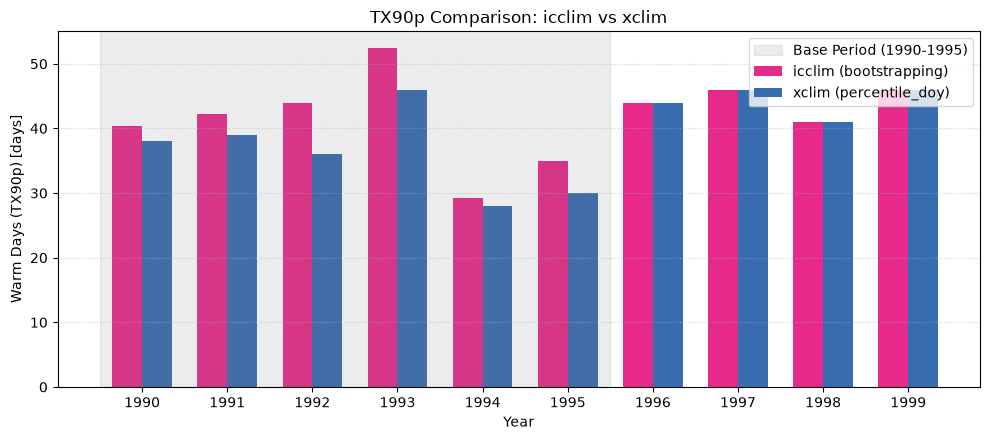

Correlation between icclim and xclim outputs: 0.8955
Mean absolute difference: 2.62 days


In [5]:
# Visual comparison between icclim and xclim percentiles
years = [t.year for t in pd.to_datetime(tx90p_icclim.time.values)]

plt.figure(figsize=(10, 4.5))
bar_width = 0.35
x_idx = np.arange(len(years))

plt.bar(
    x_idx - bar_width / 2,
    tx90p_icclim.values,
    width=bar_width,
    label="icclim (bootstrapping)",
    color="#e7298a",
)
plt.bar(
    x_idx + bar_width / 2,
    tx90p_xclim.values.squeeze(),
    width=bar_width,
    label="xclim (percentile_doy)",
    color="#386cb0",
)

plt.axvspan(-0.5, 5.5, color="gray", alpha=0.15, label="Base Period (1990-1995)")
plt.xticks(x_idx, years)
plt.xlabel("Year")
plt.ylabel("Warm Days (TX90p) [days]")
plt.title("TX90p Comparison: icclim vs xclim")
plt.legend(loc="upper right")
plt.grid(axis="y", ls=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Quantify closeness
corr = np.corrcoef(tx90p_icclim.values, tx90p_xclim.values.squeeze())[0, 1]
print(f"Correlation between icclim and xclim outputs: {corr:.4f}")
print("Mean absolute difference:", np.mean(np.abs(tx90p_icclim.values - tx90p_xclim.values.squeeze())), "days")

## 4. Multi-variable Temperature Range Indicators

Both engines provide multi-variable indices operating across simultaneous variables:
- **Diurnal Temperature Range (`dtr` in icclim vs `daily_temperature_range` in xclim)**: Mean daily difference between maximum and minimum temperature ($TX - TN$).
- **Extreme Temperature Range (`etr` in icclim vs `extreme_temperature_range` in xclim)**: Intra-period difference between the period's highest maximum and lowest minimum temperature ($TX_x - TN_n$).

In [6]:
# 1. Diurnal Temperature Range (DTR)
dtr_icclim = indicators.dtr(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")
dtr_xclim = indicators.daily_temperature_range(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")

np.testing.assert_allclose(dtr_icclim.values, dtr_xclim.values)
print("DTR is numerically identical between icclim and xclim.")

# 2. Extreme Temperature Range (ETR)
etr_icclim = indicators.etr(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")
etr_xclim = indicators.extreme_temperature_range(tasmax=ds["tasmax"], tasmin=ds["tasmin"], freq="YS")

np.testing.assert_allclose(etr_icclim.values, etr_xclim.values)
print("ETR is numerically identical between icclim and xclim.")

# Comparative summary table
df_ranges = pd.DataFrame({
    "Year": [t.year for t in pd.to_datetime(dtr_icclim.time.values)],
    "icclim DTR [degC]": np.round(dtr_icclim.values, 2),
    "xclim DTR [degC]": np.round(dtr_xclim.values, 2),
    "icclim ETR [degC]": np.round(etr_icclim.values, 2),
    "xclim ETR [degC]": np.round(etr_xclim.values, 2),
})
df_ranges

DTR is numerically identical between icclim and xclim.
ETR is numerically identical between icclim and xclim.


,Year,icclim DTR [degC],xclim DTR [degC],icclim ETR [degC],xclim ETR [degC]
0,1990,10.11,10.11,44.11,44.11
1,1991,9.74,9.74,45.23,45.23
2,1992,10.11,10.11,46.61,46.61
3,1993,10.28,10.28,43.66,43.66
4,1994,9.36,9.36,46.79,46.79
5,1995,9.74,9.74,45.55,45.55
6,1996,9.87,9.87,47.53,47.53
7,1997,9.94,9.94,47.91,47.91
8,1998,10.27,10.27,44.26,44.26
9,1999,9.97,9.97,45.22,45.22


## 5. Parallel Execution and Dask Chunking

Both `icclim` and `xclim` integrated in `earthkit-climate` preserve Dask chunking and lazy execution, enabling processing of large distributed datasets without loading entire cubes into memory.

In [7]:
# Chunk the dataset along the time dimension
ds_dask = ds.chunk({"time": 365})
print("Chunked DataArray:", ds_dask["tasmax"].data)

# Compute summer days lazily
res_lazy_su = indicators.su(ds_dask["tasmax"], freq="YS")
print("Has Dask computational graph:", hasattr(res_lazy_su.data, "dask"))

# Compute values on demand
computed_su = res_lazy_su.compute()
print("Computed values across years:", computed_su.values)

Chunked DataArray: dask.array<xarray-tasmax, shape=(3652,), dtype=float64, chunksize=(365,), chunktype=numpy.ndarray>
Has Dask computational graph: True
Computed values across years: [115. 113. 115. 112. 106. 111. 113. 119. 128. 113.]


## 6. Engine Selection Guide

| Criterion | Choose `icclim` | Choose `xclim` |
| :--- | :--- | :--- |
| **Catalog Scope** | Standard 49 ECA&D and C3S climate indices. | Broad catalog (>80 indices) including SPEI, fire weather, degree-days. |
| **Percentile Baseline** | Automatic in-base bootstrapping with 5-day running window (`base_period_time_range`). | Flexible precomputed percentiles (`tasmax_per`) from external climatologies. |
| **Data Resampling** | Direct Pandas/Xarray resampling. | Fast resampling powered by `flox`. |
| **Output Naming** | Official ECA&D short names (e.g. `SU`, `FD`, `TX90p`, `CDD`). | CF-standard names and descriptive identifiers (`summer_days`, `frost_days`). |
| **earthkit-climate Mode** | Explicit `backend="icclim"` or via short aliases (`fd`, `su`, `cdd`). | Explicit `backend="xclim"` or via descriptive names (`frost_days`). |